In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_mark": previous_mark,
    "final_score": final_score
})

df.loc[0:5, "study_hours"] = np.nan
df.loc[99, "study_hours"] = 50
df.loc[98, "attendance"] = -10

print(df.head(100))
print("\nDataset shape:", df.shape)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]

Dataset shape: (100, 4)


In [4]:
print(df.head())

   study_hours  attendance  previous_mark  final_score
0          NaN   70.846293      75.366810    35.178989
1          NaN   80.793547      78.411768    39.481248
2          NaN   81.572855      86.245769    48.605167
3          NaN   76.977227      85.807031    47.329456
4          NaN   83.387143      49.334959    37.044473


In [5]:
print(df[df["study_hours"] == 50])


    study_hours  attendance  previous_mark  final_score
99         50.0   73.570297      79.444433     46.41447


In [6]:
print(df["study_hours"].describe())


count    94.000000
mean      5.218916
std       5.014751
min      -0.239490
25%       3.731467
50%       4.812342
75%       5.744365
max      50.000000
Name: study_hours, dtype: float64


In [7]:
clean_df = df.copy()

median_hours = clean_df.loc[
    clean_df["study_hours"] != 50,
    "study_hours"
].median()

clean_df.loc[
    clean_df["study_hours"] == 50,
    "study_hours"
] = median_hours

print(clean_df.loc[99])

study_hours       4.768703
attendance       73.570297
previous_mark    79.444433
final_score      46.414470
Name: 99, dtype: float64


In [8]:
X = clean_df[
    ["study_hours", "attendance", "previous_mark"]
]

y = clean_df["final_score"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (100, 3)
Target shape: (100,)


In [9]:
clean_df = df.copy()
clean_df.loc[clean_df["study_hours"] == 50, "study_hours"] = np.nan

clean_df.loc[clean_df["attendance"] < 0, "attendance"] = np.nan

clean_df["study_hours"] = clean_df["study_hours"].fillna(
    clean_df["study_hours"].median()
)

clean_df["attendance"] = clean_df["attendance"].fillna(
    clean_df["attendance"].median()
)


X = clean_df[["study_hours", "attendance", "previous_mark"]]
y = clean_df["final_score"]

print("Cleaned dataset shape:", clean_df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nMissing values:")
print(clean_df.isnull().sum())

Cleaned dataset shape: (100, 4)
Feature matrix shape: (100, 3)
Target shape: (100,)

Missing values:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64


In [10]:

summary = clean_df.agg(["mean", "median", "std"]).T
print(summary.round(2))

                mean  median    std
study_hours     4.74    4.77   1.77
attendance     85.23   86.00   9.54
previous_mark  70.97   71.47  16.26
final_score    42.69   42.76   6.09


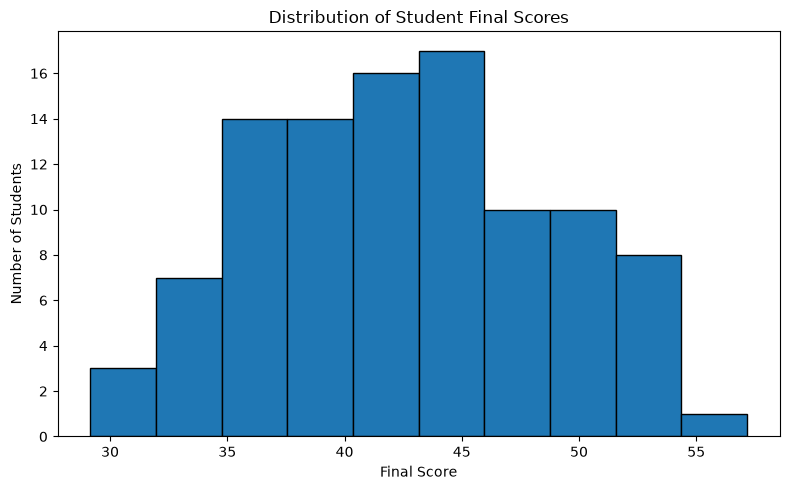

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["final_score"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Student Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

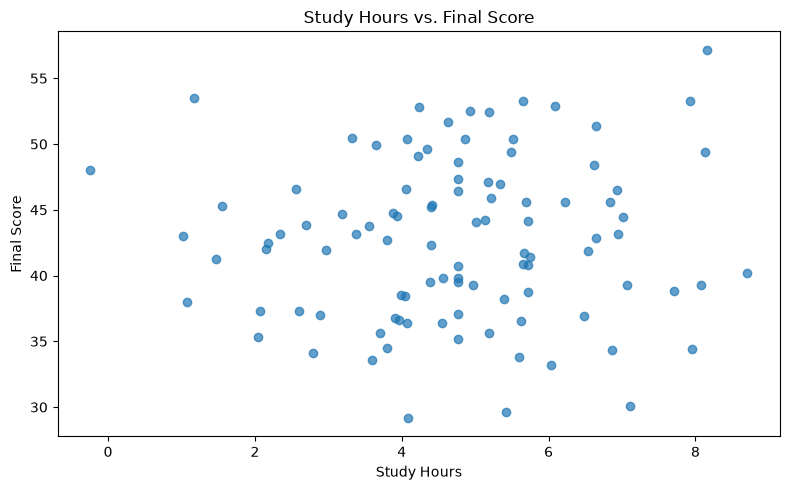

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["study_hours"],
    clean_df["final_score"],
    alpha=0.7
)

plt.title("Study Hours vs. Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.tight_layout()
plt.show()

In [13]:
correlation = clean_df["study_hours"].corr(
    clean_df["final_score"]
)

print("Pearson correlation:", round(correlation, 3))

Pearson correlation: 0.05


The Pearson correlation coefficient between study hours and final scores is 0.05. This indicates a very weak positive linear relationship between the two variables. In this dataset, the number of hours a student studies has almost no linear association with their final score.
However, correlation does not imply causation, and this result does not prove that studying has no effect on academic performance. Other factors, such as attendance, previous marks, study quality, and prior knowledge, may also influence final scores. Furthermore, this is a synthetic dataset, so the observed relationship may differ from real-world student performance.

In [14]:
x = X.iloc[0].to_numpy()
w = np.array([0.5, 0.2, 0.4])
b = 5

y_pred = np.dot(w, x) + b

print("Feature vector x:", x)
print("Weight vector w:", w)
print("Bias:", b)
print("Predicted value:", round(y_pred, 2))

Feature vector x: [ 4.76870344 70.84629258 75.36681041]
Weight vector w: [0.5 0.2 0.4]
Bias: 5
Predicted value: 51.7


The weight vector represents the contribution assigned to each feature when calculating a predicted score. Each weight multiplies its corresponding feature. The bias is a constant added to the weighted sum, allowing the prediction to shift up or down independently of the feature values.

In [15]:
scaled_df = clean_df.copy()

columns_to_scale = ["study_hours", "previous_mark"]

for col in columns_to_scale:
    mean = scaled_df[col].mean()
    std = scaled_df[col].std()

    scaled_df[col + "_standardized"] = (
        scaled_df[col] - mean
    ) / std

print(
    scaled_df[
        [
            "study_hours",
            "study_hours_standardized",
            "previous_mark",
            "previous_mark_standardized"
        ]
    ].head()
)

   study_hours  study_hours_standardized  previous_mark  \
0     4.768703                  0.016404      75.366810   
1     4.768703                  0.016404      78.411768   
2     4.768703                  0.016404      86.245769   
3     4.768703                  0.016404      85.807031   
4     4.768703                  0.016404      49.334959   

   previous_mark_standardized  
0                    0.270124  
1                    0.457342  
2                    0.939012  
3                    0.912037  
4                   -1.330433  


In [16]:
print("Original feature ranges:")
print(
    clean_df[["study_hours", "previous_mark"]].agg(
        ["min", "max"]
    ).round(2)
)

print("\nStandardized feature ranges:")
print(
    scaled_df[
        ["study_hours_standardized", "previous_mark_standardized"]
    ].agg(["min", "max"]).round(2)
)

Original feature ranges:
     study_hours  previous_mark
min        -0.24          21.38
max         8.70         127.79

Standardized feature ranges:
     study_hours_standardized  previous_mark_standardized
min                     -2.81                       -3.05
max                      2.23                        3.49


K-Nearest Neighbors calculates distances between data points. If features have very different numerical ranges, the feature with the larger range can dominate the distance calculation. Standardizing study hours and previous marks puts them on comparable scales, allowing both features to contribute more fairly to distance calculations.
